# 00 · Data exploration of Elliptic++ (transactions)

This notebook presents the raw dataset: what it contains, how the classes are distributed over time, how the transaction graph is built, what the economic columns look like, how correlated the features are, and what a piece of the graph looks like. Its plots and tables are written for the first chapter of the report.

**Input** (in `DATA_PATH` on Google Drive): the three raw files of Elliptic++ — `txs_features.csv`, `txs_classes.csv`, `txs_edgelist.csv`. The notebook uses **no file produced by later steps**: every graph measure it needs (degrees, components, neighbours) is computed here from the edge list.

**Output**
- plots in `DATA_PATH/plots/`, prefixed with `00_` (PNG, at most 1200 × 800 pixels and 200 KB);
- tables in `DATA_PATH/00-data-exploration/` (small CSV files, ready for the tables of the report).

| # | Content | Plot | Table |
|---|---|---|---|
| 1 | dataset card | | `dataset_card.csv` |
| 2 | classes overall | `00_class_share.png` | `class_counts.csv` |
| 3 | classes per time step | `00_classes_per_timestep.png` | `per_timestep.csv` |
| 4 | classes per split (train, validation, test) | `00_split_prevalence.png` | `split_composition.csv` |
| 5 | size and structure of the graph per time step | `00_graph_size_per_timestep.png` | `per_timestep.csv`, `graph_checks.csv` |
| 6 | who is linked to whom | `00_neighbor_classes.png` | `neighbor_classes.csv` |
| 7 | what is lost without the unknown nodes | `00_without_unknown.png` | `without_unknown.csv` |
| 8 | the Elliptic++ columns: copies and missing rows | | `econ_copies.csv`, `missing_econ.csv` |
| 9 | the economic columns by class | `00_econ_by_class.png` | |
| 10 | correlation of the features | `00_corr_all.png`, `00_corr_econ.png`, `00_econ_vs_local.png` | `econ_vs_local.csv` |
| 11 | a piece of the transaction graph | `00_dag_example.png` | |

**Colours**, the same in every plot of the report: **illicit = red**, **licit = blue**, **unknown = light grey**. Unknown is grey on purpose: it is not a third class, it is the absence of a label.

**How to run it.** A CPU runtime is enough; `Runtime → Run all`, a few minutes. Every plot is shown in the notebook. A plot or table that already exists on Drive is not overwritten; set `FORCE_RECOMPUTE = True` (section 0) to write them again.

**Split used in the whole project** (by time, never shuffled): train = time steps 1–30, validation = 31–40, test = 41–49.

## 0. Setup

In [1]:
# Connect Google Drive: every input and output of the project lives in DATA_PATH.
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')

DATA_PATH = Path('/content/drive/MyDrive/UNIVERSITA/block-crypto/data')
OUT_DIR = DATA_PATH / '00-data-exploration'   # tables of this notebook
PLOT_DIR = DATA_PATH / 'plots'                # plots of every step, prefixed with the step number
LOCAL_INPUT = Path('/content/input')          # local copy of the input files

Mounted at /content/drive


In [2]:
# Copy the three raw files from Drive to the Colab disk: reading a local file is much faster.
import shutil

LOCAL_INPUT.mkdir(exist_ok=True)
INPUT_FILES = {}
for name in ['txs_features.csv', 'txs_classes.csv', 'txs_edgelist.csv']:
    source, target = DATA_PATH / name, LOCAL_INPUT / name
    assert source.exists(), f'{source} is missing'
    if not target.exists() or target.stat().st_size != source.stat().st_size:
        shutil.copy(source, target)
    INPUT_FILES[name] = target
    print(f'{name}: {target.stat().st_size / 1e6:,.0f} MB')

txs_features.csv: 695 MB
txs_classes.csv: 2 MB
txs_edgelist.csv: 4 MB


In [3]:
import os
import time

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from PIL import Image
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform

TRAIN_STEPS, VAL_STEPS, TEST_STEPS = range(1, 31), range(31, 41), range(41, 50)
SPLITS = {'train': TRAIN_STEPS, 'validation': VAL_STEPS, 'test': TEST_STEPS}
CLASSES = ['illicit', 'licit', 'unknown']
CLASS_CODE = {1: 'illicit', 2: 'licit', 3: 'unknown'}   # codes of txs_classes.csv
DAG_SEED = 0          # chooses the transaction drawn in section 11
FORCE_RECOMPUTE = False

OUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

In [4]:
# Colours. Classes: red, blue, light grey. Families of features (correlation plots): aqua, yellow, violet.
# Single series that are neither a class nor a family: dark grey. Text always in ink colours.
SURFACE, INK, INK_2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
CLASS_COLOR = {'illicit': '#e34948', 'licit': '#2a78d6', 'unknown': '#d4d3cc'}
FAMILY_COLOR = {'LF': '#1baf7a', 'AF': '#eda100', 'D': '#6250d6'}
NEUTRAL = '#52514e'
RHO_CMAP = LinearSegmentedColormap.from_list(   # diverging: blue (negative) - grey (0) - red (positive)
    'rho', ['#184f95', '#2a78d6', '#9ec5f4', '#f0efec', '#f2b1ad', '#e34948', '#a52a2a'])
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'text.color': INK, 'axes.labelcolor': INK_2, 'xtick.color': INK_2, 'ytick.color': INK_2,
    'axes.edgecolor': AXIS, 'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False,
})
MAX_PIXELS, MAX_KB = (1200, 800), 200


def atomic(path, write):
    """Write through a temporary file, then rename it: no half-written file on Drive."""
    tmp = path.with_name(path.name + '.tmp')
    write(tmp)
    os.replace(tmp, path)


def save_table(df, name):
    """Show a table and write it to OUT_DIR (unless it is already there)."""
    display(df)
    path = OUT_DIR / name
    if path.exists() and not FORCE_RECOMPUTE:
        print(f'{name} is already on Drive: not overwritten.')
    else:
        atomic(path, lambda tmp: df.to_csv(tmp, index=False, float_format='%.6g'))
        print(f'{name} written.')


def save_png(fig, name):
    """Show a figure and save it at 100 dpi: at most 1200 x 800 pixels and 200 KB
    (a 256-colour PNG if the full-colour one is too big). An existing plot is not overwritten."""
    width, height = fig.get_size_inches() * 100
    assert width <= MAX_PIXELS[0] + 0.5 and height <= MAX_PIXELS[1] + 0.5, 'figure too large'
    path = PLOT_DIR / name
    if path.exists() and not FORCE_RECOMPUTE:
        plt.show()
        plt.close(fig)
        print(f'{name} is already on Drive: not overwritten.')
        return
    tmp = path.with_name(path.name + '.tmp')
    fig.savefig(tmp, dpi=100, format='png')
    plt.show()
    plt.close(fig)
    if tmp.stat().st_size > MAX_KB * 1000:
        with Image.open(tmp) as image:
            small = image.convert('RGB').quantize(256)
        small.save(tmp, format='PNG', optimize=True)
    size = tmp.stat().st_size / 1000
    assert size <= MAX_KB, f'{name}: {size:.0f} KB'
    os.replace(tmp, path)
    print(f'{name} written ({size:.0f} KB).')


def titles(fig, title, subtitle, top=0.97):
    fig.text(0.02, top, title, fontsize=13, weight='bold', ha='left', va='top')
    fig.text(0.02, top - 0.045 * 8 / fig.get_size_inches()[1], subtitle, fontsize=9, color=INK_2,
             ha='left', va='top', linespacing=1.4)


def split_lines(ax, labels=True):
    """Vertical hairlines between train, validation and test, with the names of the splits on top."""
    for boundary in [30.5, 40.5]:
        ax.axvline(boundary, color=INK_2, linewidth=0.8)
    if labels:
        for name, steps in SPLITS.items():
            ax.text((steps.start + steps.stop - 1) / 2, 1.02, name, transform=ax.get_xaxis_transform(),
                    ha='center', va='bottom', fontsize=8.5, color=INK_2)

### The measures of this notebook

All of them are computed from the three raw files.

- **Neighbours.** Two transactions are neighbours if an edge links them, in either direction ($u \to v$: the money of $u$ goes into $v$). For a class $c$, the share of neighbours of class $c'$ is
$$s(c \to c') = \frac{\#\{\text{edge ends whose node has class } c \text{ and whose other end has class } c'\}}{\#\{\text{edge ends whose node has class } c\}} .$$
If illicit transactions were mostly linked to illicit ones (*homophily*), $s(\text{illicit} \to \text{illicit})$ would be high; if they are mostly linked to the other classes, the graph is *heterophilous* for them.
- **Spearman correlation** of two columns: the Pearson correlation of their ranks, $\rho(x, y) = \operatorname{corr}(\operatorname{rank} x, \operatorname{rank} y)$. It measures whether two columns order the transactions in the same way, whatever their scale, which matters with the very long tails of these columns.
- **Reordering of the correlation matrix.** The columns are grouped by average-linkage hierarchical clustering with the distance $1 - |\rho|$: columns that are nearly copies of each other end up side by side and form visible blocks.
- **Layers of the DAG drawing.** In a directed acyclic graph every node gets a layer: the sources (no incoming edge) are layer 0, and every other node is one layer after the furthest node that pays it. Drawing the layers from left to right, every arrow points to the right: the money flows from left to right.

In [5]:
def neighbor_shares(cls, src, dst):
    """For each class (rows), the counts and shares of the classes of its neighbours (edge ends, both directions)."""
    ends = pd.DataFrame({'node_class': np.concatenate([cls[src], cls[dst]]),
                         'neighbor_class': np.concatenate([cls[dst], cls[src]])})
    counts = pd.crosstab(ends['node_class'], ends['neighbor_class']).reindex(index=CLASSES, columns=CLASSES, fill_value=0)
    return counts, counts.div(counts.sum(axis=1), axis=0)


def without_unknown(cls, src, dst):
    """What is left of the graph when the unknown nodes (and their edges) are removed."""
    labeled = cls != 'unknown'
    keep = labeled[src] & labeled[dst]
    has_neighbor = np.zeros(len(cls), dtype=bool)
    has_neighbor[src[keep]] = has_neighbor[dst[keep]] = True
    has_any = np.zeros(len(cls), dtype=bool)
    has_any[src] = has_any[dst] = True
    rows = [('edges', len(src), int(keep.sum()))]
    for name, mask in [('labeled nodes with a neighbour', labeled),
                       ('illicit nodes with a neighbour', cls == 'illicit'),
                       ('licit nodes with a neighbour', cls == 'licit')]:
        rows.append((name, int((mask & has_any).sum()), int((mask & has_neighbor).sum())))
    df = pd.DataFrame(rows, columns=['measure', 'full graph', 'without unknown'])
    df['kept'] = df['without unknown'] / df['full graph']
    return df


def layered_layout(graph):
    """Positions for drawing a DAG in layers from left to right (x = layer). Inside a layer the nodes are ordered
    by the mean height of the nodes that pay them (fewer crossing arrows)."""
    pos = {}
    for x, layer in enumerate(nx.topological_generations(graph)):
        key = {v: np.mean([pos[u][1] for u in graph.predecessors(v)]) if graph.in_degree(v) else 0.0 for v in layer}
        ordered = sorted(layer, key=lambda v: (key[v], v))
        for i, v in enumerate(ordered):
            pos[v] = (x, i - (len(ordered) - 1) / 2)
    return pos


def spearman(df):
    """Spearman correlation matrix of the columns of a table (no missing values): Pearson correlation of the ranks."""
    ranks = np.empty(df.shape, dtype=np.float32)
    for k, col in enumerate(df.columns):
        r = df[col].rank().to_numpy(np.float64)
        r -= r.mean()
        norm = np.sqrt(r @ r)
        ranks[:, k] = r / norm if norm > 0 else 0.0
    return pd.DataFrame(np.clip(ranks.T @ ranks, -1, 1), index=df.columns, columns=df.columns)

### Test on a toy graph

Eight transactions, eight edges, all classes present. The expected values are counted by hand:
- the illicit nodes 0 and 5 have five neighbours in total: three unknown and two licit, no illicit one;
- without the unknown nodes only the edges 0 → 4 and 4 → 5 survive (2 of 8), and 3 of the 5 labeled nodes keep a neighbour;
- in the layered drawing every arrow points to the right, with node 0 in the first layer and node 7 in the last one;
- a column and its reverse have Spearman $\rho = -1$; a column and its cube have $\rho = 1$.

In [6]:
toy_cls = np.array(['illicit', 'licit', 'unknown', 'unknown', 'licit', 'illicit', 'unknown', 'licit'])
toy_src = np.array([0, 0, 2, 1, 3, 4, 5, 6])
toy_dst = np.array([2, 4, 1, 3, 5, 5, 6, 7])

counts, shares = neighbor_shares(toy_cls, toy_src, toy_dst)
assert counts.loc['illicit'].tolist() == [0, 2, 3] and np.isclose(shares.loc['illicit', 'unknown'], 0.6)

lost = without_unknown(toy_cls, toy_src, toy_dst).set_index('measure')
assert lost.loc['edges', 'without unknown'] == 2
assert tuple(lost.loc['labeled nodes with a neighbour', ['full graph', 'without unknown']]) == (5, 3)

toy_graph = nx.DiGraph(zip(toy_src.tolist(), toy_dst.tolist()))
pos = layered_layout(toy_graph)
assert all(pos[u][0] < pos[v][0] for u, v in toy_graph.edges)
assert pos[0][0] == 0 and pos[7][0] == max(x for x, _ in pos.values())

x = pd.Series(np.arange(10.0))
rho = spearman(pd.DataFrame({'x': x, 'reverse': -x, 'cube': x ** 3}))
assert np.isclose(rho.loc['x', 'reverse'], -1) and np.isclose(rho.loc['x', 'cube'], 1)
print('Toy test passed.')

Toy test passed.


## 1. Load the raw files and the dataset card

`txs_features.csv` has one row per transaction: `txId`, `Time step`, 93 **Local** features (`Local_feature_1..93`, anonymous: information about the transaction itself), 72 **Aggregate** features (`Aggregate_feature_1..72`, anonymous: summaries of the neighbours), and 17 columns added by Elliptic++ with **economic data** that have a name (amounts in BTC, fees, size, numbers of addresses, degrees). `txs_classes.csv` gives the class of each transaction, `txs_edgelist.csv` the edges: $u \to v$ means that an output of $u$ is spent by $v$.

In [7]:
start = time.time()
header = pd.read_csv(INPUT_FILES['txs_features.csv'], nrows=0).columns.tolist()
LF = [c for c in header if c.startswith('Local_feature_')]
AF = [c for c in header if c.startswith('Aggregate_feature_')]
EPP = header[2 + len(LF) + len(AF):]   # the 17 columns added by Elliptic++
assert header[:2] == ['txId', 'Time step'] and len(LF) == 93 and len(AF) == 72 and len(EPP) == 17
features = pd.read_csv(INPUT_FILES['txs_features.csv'],
                       dtype={c: np.float32 for c in LF + AF} | {c: np.float64 for c in EPP})
classes = pd.read_csv(INPUT_FILES['txs_classes.csv'])
edges = pd.read_csv(INPUT_FILES['txs_edgelist.csv'])
print(f'Files read in {time.time() - start:.0f}s.')

N = len(features)
TXID = features['txId'].to_numpy()
STEP = features['Time step'].to_numpy()
code_of = features[['txId']].merge(classes, on='txId', how='left', validate='one_to_one')['class']
assert code_of.notna().all(), 'a transaction has no class'
CLS = code_of.map(CLASS_CODE).to_numpy()
row_of = pd.Index(TXID)
SRC, DST = row_of.get_indexer(edges.iloc[:, 0]), row_of.get_indexer(edges.iloc[:, 1])
assert (SRC >= 0).all() and (DST >= 0).all(), 'an edge points to an unknown transaction'
HAS_ECON = features[EPP].notna().all(axis=1).to_numpy()
print(f'{N:,} transactions, {len(SRC):,} edges, {STEP.max()} time steps.')

Files read in 12s.
203,769 transactions, 234,355 edges, 49 time steps.


In [8]:
nodes_per_step = pd.Series(STEP).value_counts().sort_index()
edges_per_step = pd.Series(STEP[SRC]).value_counts().reindex(nodes_per_step.index, fill_value=0)
class_counts = pd.Series(CLS).value_counts().reindex(CLASSES)
card = [
    ('transactions (nodes)', N), ('edges', len(SRC)), ('time steps', int(STEP.max())),
    ('Local features (anonymous)', len(LF)), ('Aggregate features (anonymous)', len(AF)),
    ('columns added by Elliptic++ (named)', len(EPP)),
    *[(f'{c} transactions', int(class_counts[c])) for c in CLASSES],
    ('labeled transactions', int(class_counts['illicit'] + class_counts['licit'])),
    ('transactions per time step: min', int(nodes_per_step.min())),
    ('transactions per time step: median', int(nodes_per_step.median())),
    ('transactions per time step: max', int(nodes_per_step.max())),
    ('transactions without the Elliptic++ data', int((~HAS_ECON).sum())),
]
save_table(pd.DataFrame(card, columns=['item', 'value']), 'dataset_card.csv')

,item,value
0,transactions (nodes),203769
1,edges,234355
2,time steps,49
3,Local features (anonymous),93
4,Aggregate features (anonymous),72
5,columns added by Elliptic++ (named),17
6,illicit transactions,4545
7,licit transactions,42019
8,unknown transactions,157205
9,labeled transactions,46564


dataset_card.csv written.


## 2. Classes overall

77% of the transactions have no label. Among the labeled ones, roughly one in ten is illicit: the problem is strongly **imbalanced**.

,class,transactions,share of all,share of labeled
0,illicit,4545,0.022305,0.097608
1,licit,42019,0.206209,0.902392
2,unknown,157205,0.771486,NaN


class_counts.csv written.


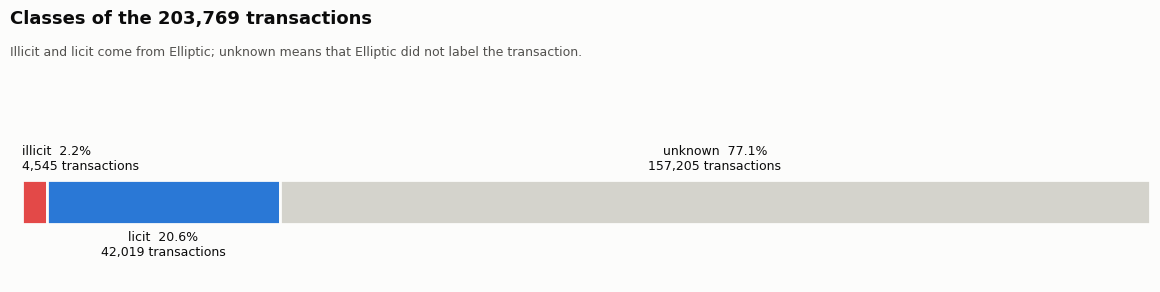

00_class_share.png written (25 KB).


In [9]:
table = pd.DataFrame({'class': CLASSES, 'transactions': class_counts.to_numpy()})
table['share of all'] = table['transactions'] / N
labeled_total = table.loc[table['class'] != 'unknown', 'transactions'].sum()
table['share of labeled'] = np.where(table['class'] != 'unknown', table['transactions'] / labeled_total, np.nan)
save_table(table, 'class_counts.csv')

fig, ax = plt.subplots(figsize=(12, 3.2))
fig.subplots_adjust(left=0.03, right=0.97, top=0.62, bottom=0.12)
left = 0
for i, row in table.iterrows():
    width = row['share of all']
    ax.barh(0, width, left=left, height=0.5, color=CLASS_COLOR[row['class']], edgecolor=SURFACE, linewidth=2)
    text = f"{row['class']}  {width:.1%}\n{row['transactions']:,} transactions"
    above = i != 1   # the licit label goes below the bar, so that it never touches the illicit one
    x_text, ha = (left, 'left') if row['class'] == 'illicit' else (left + width / 2, 'center')
    ax.text(x_text, 0.33 if above else -0.33, text, ha=ha, va='bottom' if above else 'top', fontsize=9, color=INK)
    left += width
ax.set_xlim(0, 1)
ax.set_ylim(-0.9, 0.9)
ax.axis('off')
titles(fig, 'Classes of the 203,769 transactions',
       'Illicit and licit come from Elliptic; unknown means that Elliptic did not label the transaction.')
save_png(fig, '00_class_share.png')

## 3. Classes per time step

Each time step covers about two weeks. Top: how many transactions of each class it contains. Bottom: the share of illicit transactions among the **labeled** ones (with the unknown ones, the illicit share would almost disappear). After time step 43 the illicit transactions almost vanish: in the original paper of the dataset (Weber et al., 2019) this is the closure of a dark market. That is why the test set (time steps 41–49) has about half the prevalence of train and validation.

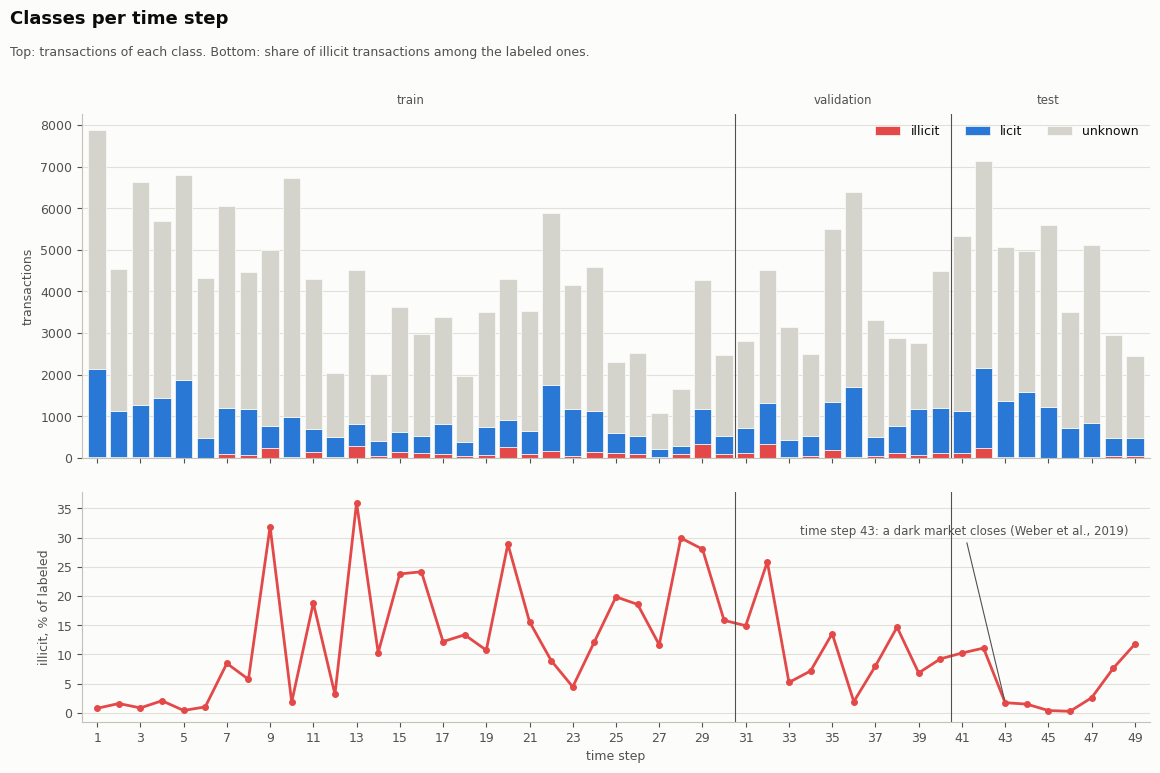

00_classes_per_timestep.png written (81 KB).


In [10]:
per_step = pd.crosstab(STEP, CLS).reindex(columns=CLASSES, fill_value=0)
per_step.index.name = 'time_step'
per_step['nodes'] = per_step[CLASSES].sum(axis=1)
per_step['edges'] = edges_per_step.to_numpy()
per_step['illicit share of labeled'] = per_step['illicit'] / (per_step['illicit'] + per_step['licit'])

steps = per_step.index.to_numpy()
fig, (top, bottom) = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={'height_ratios': [3, 2]})
fig.subplots_adjust(left=0.08, right=0.97, top=0.84, bottom=0.08, hspace=0.12)
base = np.zeros(len(steps))
for c in CLASSES:
    top.bar(steps, per_step[c], bottom=base, width=0.8, color=CLASS_COLOR[c], label=c, edgecolor=SURFACE, linewidth=0.5)
    base += per_step[c].to_numpy()
top.set_ylabel('transactions')
top.grid(axis='y', color=GRID, linewidth=0.8)
top.set_axisbelow(True)
top.legend(loc='upper right', frameon=False, ncol=3)
split_lines(top)

bottom.plot(steps, per_step['illicit share of labeled'] * 100, color=CLASS_COLOR['illicit'], linewidth=2,
            marker='o', markersize=4)
bottom.set_ylabel('illicit, % of labeled')
bottom.set_xlabel('time step')
bottom.grid(axis='y', color=GRID, linewidth=0.8)
split_lines(bottom, labels=False)
peak = per_step['illicit share of labeled'].max() * 100
bottom.annotate('time step 43: a dark market closes (Weber et al., 2019)',
                xy=(43, per_step.loc[43, 'illicit share of labeled'] * 100), xytext=(33.5, peak * 0.85),
                ha='left', fontsize=8.5, color=INK_2, arrowprops=dict(arrowstyle='-', color=INK_2, linewidth=0.8))
bottom.set_xticks(range(1, 50, 2))
bottom.set_xlim(0.3, 49.7)
titles(fig, 'Classes per time step',
       'Top: transactions of each class. Bottom: share of illicit transactions among the labeled ones.')
save_png(fig, '00_classes_per_timestep.png')

## 4. Classes per split

The project trains on time steps 1–30, chooses hyper-parameters on 31–40 and tests on 41–49. The share of illicit transactions among the labeled ones is also the PR-AUC of a random classifier, the baseline every model must beat.

The table also counts the labeled transactions **with** the Elliptic++ data: the 519 labeled ones without it are left out of loss and metrics in the training steps, so those rows are the ones the models are evaluated on.

,split,time steps,transactions,labeled,illicit,licit,illicit share of labeled,labeled with Elliptic++ data,illicit share of those
0,train,1-30,123287,26905,2954,23951,0.109794,26750,0.110430
1,validation,31-40,38316,9686,1067,8619,0.110159,9429,0.113162
2,test,41-49,42166,9973,524,9449,0.052542,9866,0.053112


split_composition.csv written.


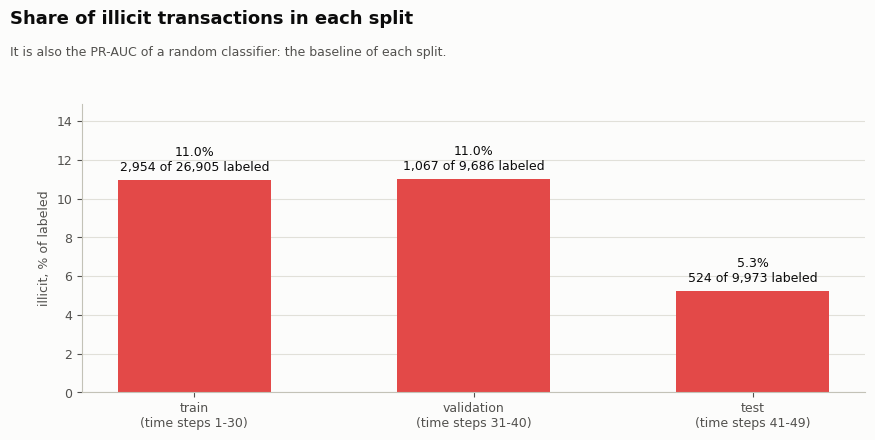

00_split_prevalence.png written (36 KB).


In [11]:
rows = []
for split, rng_ in SPLITS.items():
    in_split = np.isin(STEP, rng_)
    labeled = in_split & (CLS != 'unknown')
    rows.append({'split': split, 'time steps': f'{rng_.start}-{rng_.stop - 1}', 'transactions': int(in_split.sum()),
                 'labeled': int(labeled.sum()), 'illicit': int((in_split & (CLS == 'illicit')).sum()),
                 'licit': int((in_split & (CLS == 'licit')).sum()),
                 'illicit share of labeled': (in_split & (CLS == 'illicit')).sum() / labeled.sum(),
                 'labeled with Elliptic++ data': int((labeled & HAS_ECON).sum()),
                 'illicit share of those': (in_split & (CLS == 'illicit') & HAS_ECON).sum() / (labeled & HAS_ECON).sum()})
split_table = pd.DataFrame(rows)
save_table(split_table, 'split_composition.csv')

fig, ax = plt.subplots(figsize=(9, 4.5))
fig.subplots_adjust(left=0.1, right=0.97, top=0.76, bottom=0.12)
xs = np.arange(len(split_table))
ax.bar(xs, split_table['illicit share of labeled'] * 100, width=0.55, color=CLASS_COLOR['illicit'])
for x_, (_, r) in zip(xs, split_table.iterrows()):
    ax.text(x_, r['illicit share of labeled'] * 100 + 0.3, f"{r['illicit share of labeled']:.1%}\n"
            f"{r['illicit']:,} of {r['labeled']:,} labeled", ha='center', va='bottom', fontsize=9)
ax.set_xticks(xs, [f"{r['split']}\n(time steps {r['time steps']})" for _, r in split_table.iterrows()])
ax.set_ylabel('illicit, % of labeled')
ax.set_ylim(0, split_table['illicit share of labeled'].max() * 100 * 1.35)
ax.grid(axis='y', color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
titles(fig, 'Share of illicit transactions in each split',
       'It is also the PR-AUC of a random classifier: the baseline of each split.')
save_png(fig, '00_split_prevalence.png')

## 5. The graph, time step by time step

Checks on the whole graph (self-loops, repeated edges, isolated nodes, edges between different time steps) and, for each time step, the number of connected components (ignoring the direction of the edges), whether it is a DAG (no directed cycle: money never comes back to a transaction it came from), and the share of nodes that belong to at least one triangle (a node with clustering coefficient above 0).

The plot shows the number of edges per time step and the edges per node $m_t / n_t$. A connected graph with $n$ nodes has at least $n - 1$ edges, exactly $n - 1$ when it is a tree: a ratio close to 1 means that each time step is almost a tree.

In [12]:
graph = nx.DiGraph()
graph.add_nodes_from(range(N))
graph.add_edges_from(zip(SRC.tolist(), DST.tolist()))

step_rows = []
for t in per_step.index:
    sub = graph.subgraph(np.flatnonzero(STEP == t).tolist())
    undirected = sub.to_undirected()
    triangles = nx.triangles(undirected)
    step_rows.append({'time_step': t, 'components': nx.number_connected_components(undirected),
                      'is_dag': nx.is_directed_acyclic_graph(sub),
                      'share in a triangle': np.mean([k > 0 for k in triangles.values()])})
per_step = per_step.join(pd.DataFrame(step_rows).set_index('time_step'))
per_step['edges per node'] = per_step['edges'] / per_step['nodes']
save_table(per_step.reset_index(), 'per_timestep.csv')

pairs = pd.Series(list(zip(SRC, DST)))
in_triangle = sum(r['share in a triangle'] * per_step.loc[r['time_step'], 'nodes'] for r in step_rows) / N
checks = pd.DataFrame([
    ('self-loops', int((SRC == DST).sum())),
    ('repeated edges', int(pairs.duplicated().sum())),
    ('isolated nodes (no edge)', int(N - len(np.union1d(SRC, DST)))),
    ('edges between different time steps', int((STEP[SRC] != STEP[DST]).sum())),
    ('time steps with more than one component', int((per_step['components'] > 1).sum())),
    ('time steps that are not a DAG', int((~per_step['is_dag']).sum())),
    ('share of nodes in at least one triangle', round(float(in_triangle), 4)),
], columns=['check', 'value'])
save_table(checks, 'graph_checks.csv')

,time_step,illicit,licit,unknown,nodes,edges,illicit share of labeled,components,is_dag,share in a triangle,edges per node
0,1,17,2130,5733,7880,9164,0.007918,1,True,0.035533,1.162944
1,2,18,1099,3427,4544,5241,0.016115,1,True,0.030590,1.153389
2,3,11,1268,5342,6621,8316,0.008600,1,True,0.040326,1.256004
3,4,30,1410,4253,5693,8180,0.020833,1,True,0.075531,1.436852
4,5,8,1874,4921,6803,8623,0.004251,1,True,0.047185,1.267529
5,6,5,480,3843,4328,5242,0.010309,1,True,0.028189,1.211183
6,7,102,1101,4845,6048,7253,0.084788,1,True,0.052249,1.199239
7,8,67,1098,3292,4457,5186,0.057511,1,True,0.029392,1.163563
8,9,248,530,4218,4996,5939,0.318766,1,True,0.047638,1.188751
9,10,18,954,5755,6727,8588,0.018519,1,True,0.072395,1.276646


per_timestep.csv written.


,check,value
0,self-loops,0.0000
1,repeated edges,0.0000
2,isolated nodes (no edge),0.0000
3,edges between different time steps,0.0000
4,time steps with more than one component,0.0000
5,time steps that are not a DAG,0.0000
6,share of nodes in at least one triangle,0.0353


graph_checks.csv written.


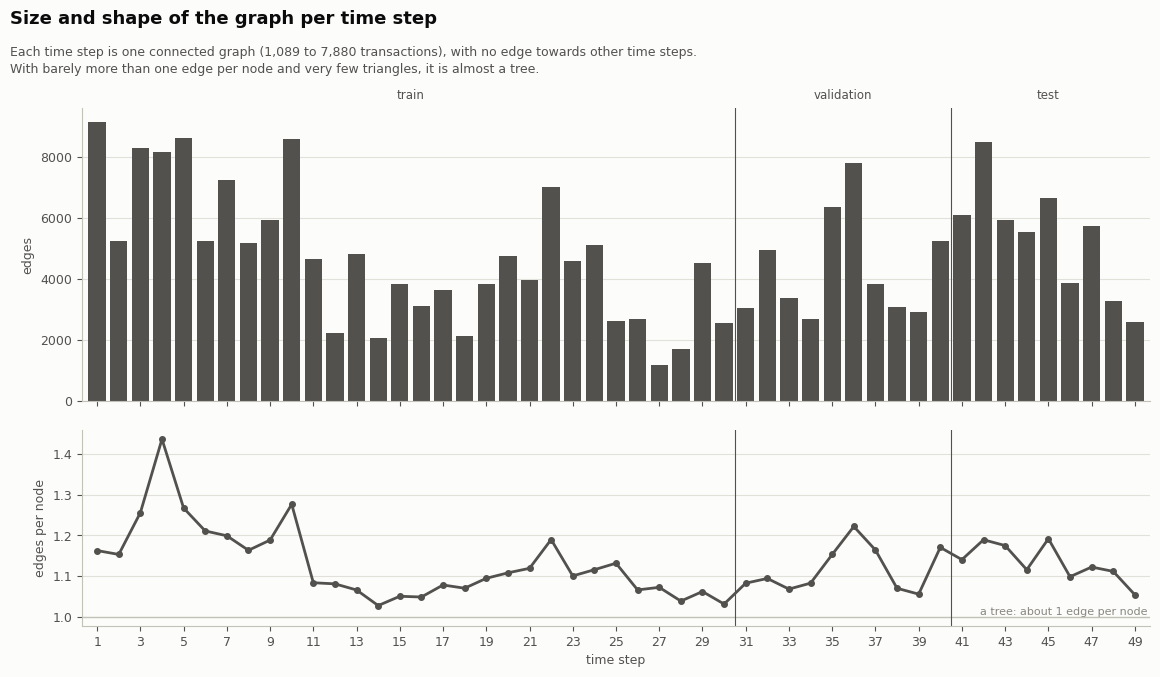

00_graph_size_per_timestep.png written (69 KB).


In [13]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={'height_ratios': [3, 2]})
fig.subplots_adjust(left=0.08, right=0.97, top=0.83, bottom=0.09, hspace=0.12)
top.bar(steps, per_step['edges'], width=0.8, color=NEUTRAL)
top.set_ylabel('edges')
top.grid(axis='y', color=GRID, linewidth=0.8)
top.set_axisbelow(True)
split_lines(top)
bottom.plot(steps, per_step['edges per node'], color=NEUTRAL, linewidth=2, marker='o', markersize=4)
bottom.axhline(1, color=AXIS, linewidth=1)
bottom.text(49.6, 1, 'a tree: about 1 edge per node', ha='right', va='bottom', fontsize=8, color=MUTED)
bottom.set_ylabel('edges per node')
bottom.set_xlabel('time step')
bottom.grid(axis='y', color=GRID, linewidth=0.8)
split_lines(bottom, labels=False)
bottom.set_xticks(range(1, 50, 2))
bottom.set_xlim(0.3, 49.7)
titles(fig, 'Size and shape of the graph per time step',
       f'Each time step is one connected graph ({per_step["nodes"].min():,} to {per_step["nodes"].max():,} transactions), '
       'with no edge towards other time steps.\nWith barely more than one edge per node and very few triangles, it is almost a tree.')
save_png(fig, '00_graph_size_per_timestep.png')

## 6. Who is linked to whom

For each class, the classes of its neighbours (section 0). Two things to read in the plot:
- **most of the neighbourhood has no label**: unknown transactions are the most common neighbours of illicit and unknown transactions, and almost half of the neighbours of licit ones;
- **the labels of the neighbours carry information**: compared with their share in the dataset, illicit transactions are linked to other illicit ones far more often than chance (the printed numbers below give the ratio), while licit ones are mostly linked to licit ones.

So a graph model can learn from the neighbours, but mostly from the features of unlabeled ones. The models that keep a node and its neighbours apart (GraphSAGE, GATv2, ChebNet) can also decide how much to trust the neighbours.

neighbor_class,class,neighbors: illicit,neighbors: licit,neighbors: unknown,share: illicit,share: licit,share: unknown
0,illicit,1996,1696,5451,0.218309,0.185497,0.596194
1,licit,1696,67860,60502,0.013040,0.521767,0.465192
2,unknown,5451,60502,263556,0.016543,0.183613,0.799845


neighbor_classes.csv written.


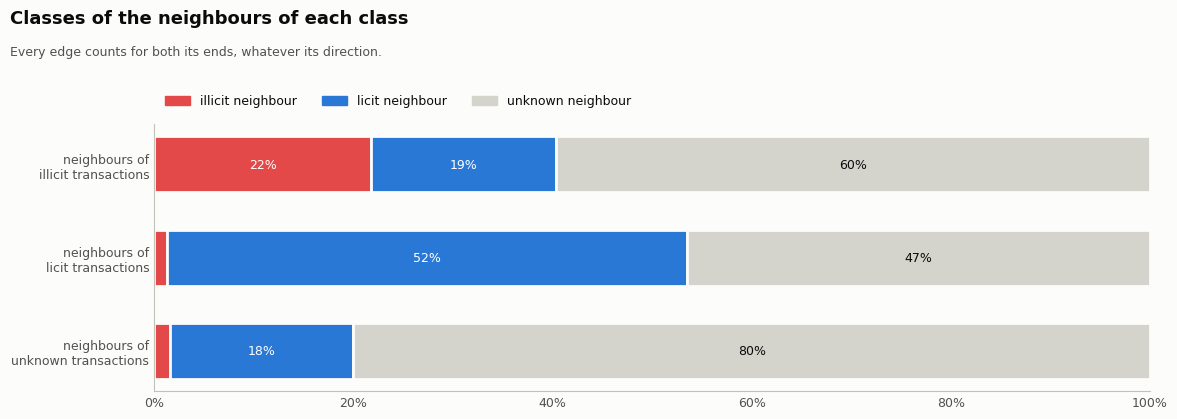

00_neighbor_classes.png written (38 KB).
Illicit transactions: 21.8% of their neighbours are illicit, 18.5% licit, 59.6% unknown.
Illicit neighbours: 10 times the share of illicit transactions in the dataset (2.2%); among the labeled neighbours, 54% are illicit.


In [14]:
counts, shares = neighbor_shares(CLS, SRC, DST)
table = counts.add_prefix('neighbors: ').join(shares.add_prefix('share: ')).reset_index().rename(columns={'node_class': 'class'})
save_table(table, 'neighbor_classes.csv')

fig, ax = plt.subplots(figsize=(12, 4.6))
fig.subplots_adjust(left=0.14, right=0.97, top=0.72, bottom=0.14)
for y_, c in enumerate(CLASSES):
    left = 0
    for c2 in CLASSES:
        width = shares.loc[c, c2]
        ax.barh(y_, width, left=left, height=0.6, color=CLASS_COLOR[c2], edgecolor=SURFACE, linewidth=2)
        if width > 0.06:
            ax.text(left + width / 2, y_, f'{width:.0%}', ha='center', va='center', fontsize=9,
                    color='#ffffff' if c2 != 'unknown' else INK)
        left += width
ax.set_yticks(range(3), [f'neighbours of\n{c} transactions' for c in CLASSES])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.tick_params(length=0)
ax.legend(handles=[Patch(color=CLASS_COLOR[c], label=f'{c} neighbour') for c in CLASSES],
          loc='lower left', bbox_to_anchor=(0, 1.02), ncol=3, frameon=False)
titles(fig, 'Classes of the neighbours of each class',
       'Every edge counts for both its ends, whatever its direction.')
save_png(fig, '00_neighbor_classes.png')
base = class_counts['illicit'] / N
labeled_neighbors = counts.loc['illicit', 'illicit'] + counts.loc['illicit', 'licit']
print(f"Illicit transactions: {shares.loc['illicit', 'illicit']:.1%} of their neighbours are illicit, "
      f"{shares.loc['illicit', 'licit']:.1%} licit, {shares.loc['illicit', 'unknown']:.1%} unknown.")
print(f"Illicit neighbours: {shares.loc['illicit', 'illicit'] / base:.0f} times the share of illicit transactions in the "
      f"dataset ({base:.1%}); among the labeled neighbours, {counts.loc['illicit', 'illicit'] / labeled_neighbors:.0%} are illicit.")

## 7. What is lost without the unknown transactions

Many works remove the unknown transactions before training. This section measures what that does to the graph: most edges disappear, and many labeled transactions, especially illicit ones, are left without any neighbour, so a graph model would see nothing around them. This is why the project keeps the unknown transactions in the graph (as structure and as neighbours) and only leaves them out of loss and metrics.

,measure,full graph,without unknown,kept
0,edges,234355,36624,0.156276
1,labeled nodes with a neighbour,46564,35874,0.770424
2,illicit nodes with a neighbour,4545,2484,0.546535
3,licit nodes with a neighbour,42019,33390,0.794641


without_unknown.csv written.


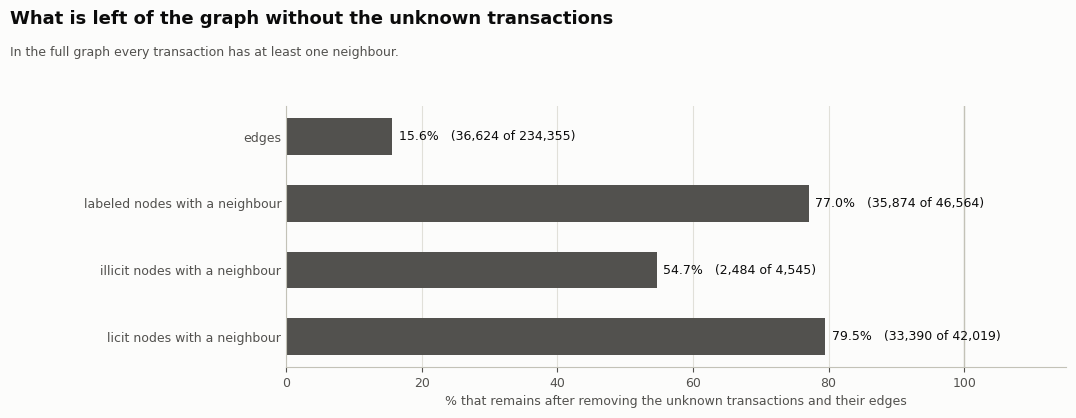

00_without_unknown.png written (46 KB).


In [15]:
lost = without_unknown(CLS, SRC, DST)
save_table(lost, 'without_unknown.csv')

fig, ax = plt.subplots(figsize=(12, 4.2))
fig.subplots_adjust(left=0.25, right=0.9, top=0.74, bottom=0.12)
ys = np.arange(len(lost))
ax.barh(ys, lost['kept'] * 100, height=0.55, color=NEUTRAL)
ax.axvline(100, color=AXIS, linewidth=1)
for y_, (_, r) in zip(ys, lost.iterrows()):
    ax.text(r['kept'] * 100 + 1, y_, f"{r['kept']:.1%}   ({r['without unknown']:,} of {r['full graph']:,})",
            va='center', fontsize=9, color=INK)
ax.set_yticks(ys, lost['measure'])
ax.invert_yaxis()
ax.set_xlim(0, 115)
ax.set_xticks(range(0, 101, 20))
ax.set_xlabel('% that remains after removing the unknown transactions and their edges')
ax.tick_params(axis='y', length=0)
ax.grid(axis='x', color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
titles(fig, 'What is left of the graph without the unknown transactions',
       'In the full graph every transaction has at least one neighbour.')
save_png(fig, '00_without_unknown.png')

## 8. The columns added by Elliptic++

Three of the 17 columns are exact copies of other information, and one is the difference of two others; the checks below confirm it (the degrees are counted here from the edge list):
- `total_BTC` = `out_BTC_total`;
- `in_txs_degree` = number of incoming edges, `out_txs_degree` = number of outgoing edges;
- `fees` = `in_BTC_total` − `out_BTC_total`.

The 17 columns are missing, all together, for some transactions: the second table shows how many, by class and split.

In [16]:
econ = features.loc[HAS_ECON]
in_degree = np.bincount(DST, minlength=N)[HAS_ECON]
out_degree = np.bincount(SRC, minlength=N)[HAS_ECON]
relative = lambda a, b: float(np.max(np.abs(a - b) / np.maximum(np.abs(b), 1e-12)))
copies = pd.DataFrame([
    ('total_BTC = out_BTC_total', relative(econ['total_BTC'], econ['out_BTC_total'])),
    ('in_txs_degree = incoming edges', float(np.max(np.abs(econ['in_txs_degree'] - in_degree)))),
    ('out_txs_degree = outgoing edges', float(np.max(np.abs(econ['out_txs_degree'] - out_degree)))),
    ('fees = in_BTC_total - out_BTC_total', relative(econ['in_BTC_total'] - econ['out_BTC_total'], econ['fees'])),
], columns=['relation', 'largest difference'])
save_table(copies, 'econ_copies.csv')

rows = []
for split, rng_ in SPLITS.items():
    m = np.isin(STEP, rng_) & ~HAS_ECON
    rows.append({'split': split, **{c: int((m & (CLS == c)).sum()) for c in CLASSES}, 'total': int(m.sum())})
missing = pd.DataFrame(rows)
missing.loc[len(missing)] = {'split': 'all', **{c: int(missing[c].sum()) for c in CLASSES}, 'total': int(missing['total'].sum())}
save_table(missing, 'missing_econ.csv')

,relation,largest difference
0,total_BTC = out_BTC_total,0.000000e+00
1,in_txs_degree = incoming edges,0.000000e+00
2,out_txs_degree = outgoing edges,0.000000e+00
3,fees = in_BTC_total - out_BTC_total,7.072231e-09


econ_copies.csv written.


,split,illicit,licit,unknown,total
0,train,0,155,140,295
1,validation,0,257,132,389
2,test,0,107,174,281
3,all,0,519,446,965


missing_econ.csv written.


## 9. The economic columns by class

The only columns with a meaning anybody can read. Each panel shows, for the labeled transactions with the Elliptic++ data, the share of transactions with a value up to $x$ (empirical cumulative distribution), illicit against licit, on a logarithmic scale. Where the two curves are far apart, the column alone already separates the classes. Values equal to 0 cannot be drawn on a log scale: their share is written in the panel.

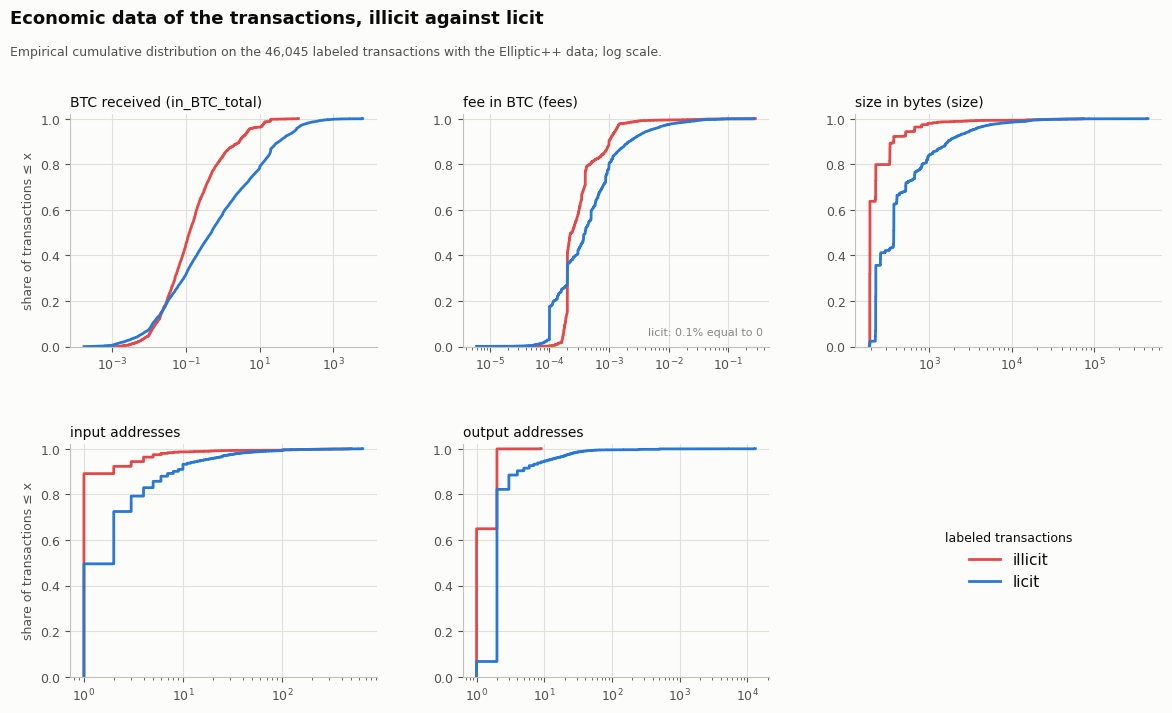

00_econ_by_class.png written (81 KB).


In [17]:
ECON_SHOWN = [('in_BTC_total', 'BTC received (in_BTC_total)'), ('fees', 'fee in BTC (fees)'), ('size', 'size in bytes (size)'),
              ('num_input_addresses', 'input addresses'), ('num_output_addresses', 'output addresses')]
fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
fig.subplots_adjust(left=0.07, right=0.98, top=0.83, bottom=0.08, wspace=0.28, hspace=0.42)
labeled = HAS_ECON & (CLS != 'unknown')
for ax, (col, label) in zip(axes.flat, ECON_SHOWN):
    zero_notes = []
    for c in ['illicit', 'licit']:
        v = features.loc[labeled & (CLS == c), col].to_numpy()
        positive = np.sort(v[v > 0])
        share = (np.sum(v <= 0) + np.arange(1, len(positive) + 1)) / len(v)   # the zeros count, even if not drawn
        ax.step(positive, share, where='post', color=CLASS_COLOR[c], linewidth=2, label=c)
        if (v <= 0).any():
            zero_notes.append(f'{c}: {np.mean(v <= 0):.1%} equal to 0')
    ax.set_xscale('log')
    ax.set_ylim(0, 1.02)
    ax.set_title(label, fontsize=10, loc='left', color=INK)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    if zero_notes:
        ax.text(0.98, 0.04, '\n'.join(zero_notes), transform=ax.transAxes, ha='right', va='bottom', fontsize=8, color=MUTED)
for ax in axes[:, 0]:
    ax.set_ylabel('share of transactions ≤ x')
axes.flat[-1].axis('off')
axes.flat[-1].legend(handles=[Line2D([], [], color=CLASS_COLOR[c], linewidth=2, label=c) for c in ['illicit', 'licit']],
                     loc='center', frameon=False, fontsize=11, title='labeled transactions', title_fontsize=9)
titles(fig, 'Economic data of the transactions, illicit against licit',
       f'Empirical cumulative distribution on the {labeled.sum():,} labeled transactions with the Elliptic++ data; log scale.')
save_png(fig, '00_econ_by_class.png')

## 10. Correlation of the features

Three views of the Spearman correlation on all transactions with the Elliptic++ data (the 165 anonymous features and the 14 economic columns that are not copies):
1. **all 179 columns**, reordered so that similar columns stand side by side (section 0), without names: the coloured strip says which family each column belongs to. Dark blocks along the diagonal are groups of nearly redundant columns;
2. **the 14 economic columns** with their values;
3. **"who is who"**: for each economic column, the most similar Local feature. Values near 1 mean that the economic column gives a **name** to information that was already in the anonymous features.

Spearman matrix 179 x 179 on 202,804 transactions in 6s.


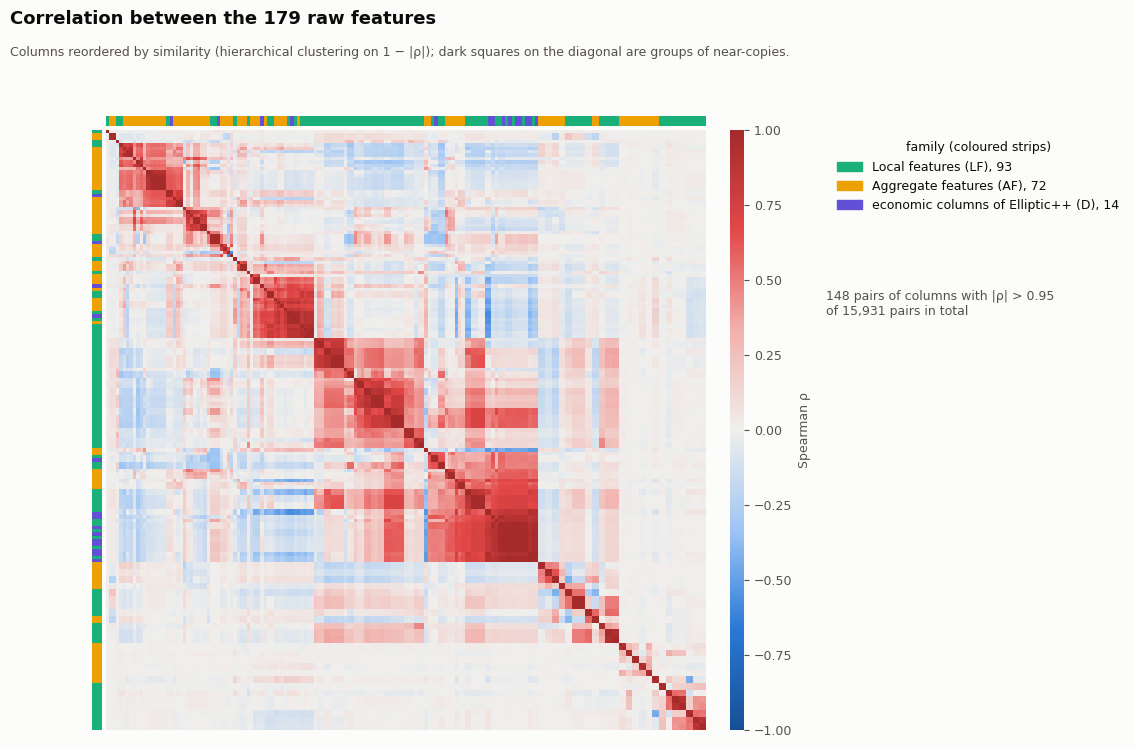

00_corr_all.png written (106 KB).


In [18]:
ECON = ['in_BTC_total', 'out_BTC_total', 'fees', 'size', 'num_input_addresses', 'num_output_addresses',
        'in_BTC_min', 'in_BTC_max', 'in_BTC_mean', 'in_BTC_median', 'out_BTC_min', 'out_BTC_max', 'out_BTC_mean', 'out_BTC_median']
assert set(ECON) | {'total_BTC', 'in_txs_degree', 'out_txs_degree'} == set(EPP)
start = time.time()
RHO = spearman(features.loc[HAS_ECON, LF + AF + ECON])
print(f'Spearman matrix {RHO.shape[0]} x {RHO.shape[1]} on {HAS_ECON.sum():,} transactions in {time.time() - start:.0f}s.')
family_of = {**{c: 'LF' for c in LF}, **{c: 'AF' for c in AF}, **{c: 'D' for c in ECON}}

distance = 1 - RHO.abs().to_numpy(np.float64)
np.fill_diagonal(distance, 0)
order = leaves_list(linkage(squareform(distance, checks=False), method='average'))
cols = RHO.columns[order]

fig = plt.figure(figsize=(12, 8))
ax = fig.add_axes([0.1, 0.07, 0.5, 0.75])                  # square: 0.5 x 12 = 0.75 x 8 inches
im = ax.imshow(RHO.loc[cols, cols].to_numpy(), cmap=RHO_CMAP, vmin=-1, vmax=1, interpolation='nearest')
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)
band = np.array([[list(FAMILY_COLOR).index(family_of[c]) for c in cols]])
family_cmap = LinearSegmentedColormap.from_list('families', list(FAMILY_COLOR.values()), N=3)
for rect, data_ in [([0.1, 0.825, 0.5, 0.012], band), ([0.088, 0.07, 0.008, 0.75], band.T)]:
    strip = fig.add_axes(rect)
    strip.imshow(data_, cmap=family_cmap, vmin=0, vmax=2, aspect='auto', interpolation='nearest')
    strip.axis('off')
cax = fig.add_axes([0.62, 0.07, 0.012, 0.75])
bar = fig.colorbar(im, cax=cax)
bar.outline.set_visible(False)
bar.set_label('Spearman ρ', color=INK_2)
fig.legend(handles=[Patch(color=FAMILY_COLOR['LF'], label=f'Local features (LF), {len(LF)}'),
                    Patch(color=FAMILY_COLOR['AF'], label=f'Aggregate features (AF), {len(AF)}'),
                    Patch(color=FAMILY_COLOR['D'], label=f'economic columns of Elliptic++ (D), {len(ECON)}')],
           loc='upper left', bbox_to_anchor=(0.7, 0.82), frameon=False, title='family (coloured strips)', title_fontsize=9)
strong = (RHO.abs().to_numpy() > 0.95).sum() - len(RHO)
fig.text(0.7, 0.62, f'{strong // 2:,} pairs of columns with |ρ| > 0.95\nof {len(RHO) * (len(RHO) - 1) // 2:,} pairs in total',
         fontsize=9, color=INK_2, va='top')
titles(fig, 'Correlation between the 179 raw features',
       'Columns reordered by similarity (hierarchical clustering on 1 − |ρ|); dark squares on the diagonal are groups of near-copies.')
save_png(fig, '00_corr_all.png')

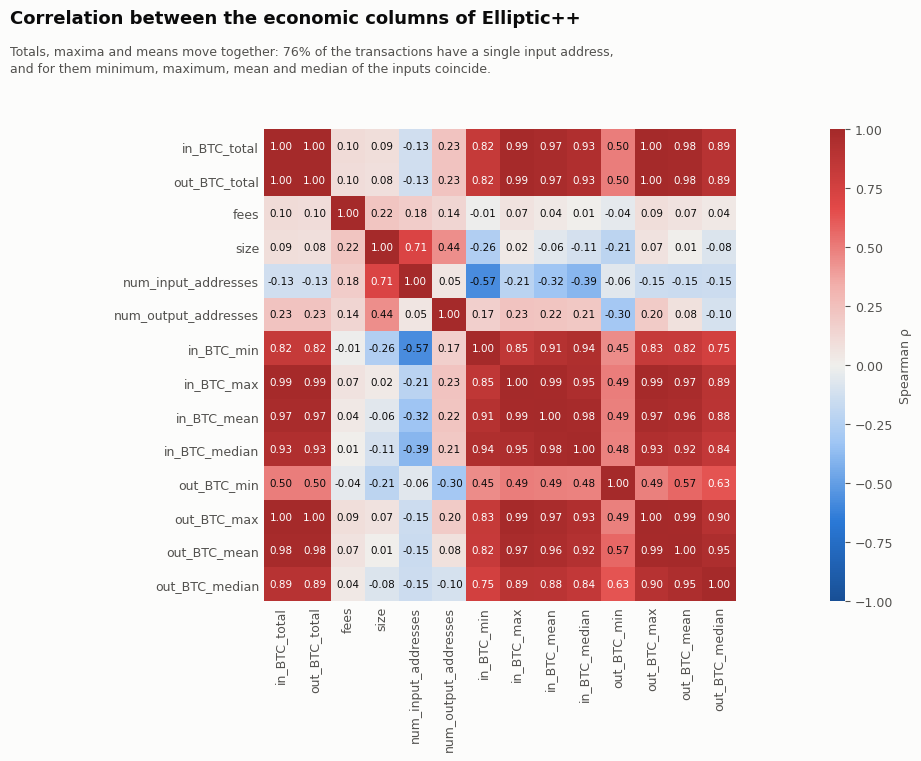

00_corr_econ.png written (136 KB).


In [19]:
sub = RHO.loc[ECON, ECON].to_numpy()
single_input = np.mean(features.loc[HAS_ECON, 'num_input_addresses'] == 1)
fig = plt.figure(figsize=(10, 8))
ax = fig.add_axes([0.22, 0.23, 0.58, 0.59])
im = ax.imshow(sub, cmap=RHO_CMAP, vmin=-1, vmax=1, interpolation='nearest')
for i in range(len(ECON)):
    for j in range(len(ECON)):
        ax.text(j, i, f'{sub[i, j]:.2f}', ha='center', va='center', fontsize=7.5,
                color='#ffffff' if abs(sub[i, j]) > 0.6 else INK)
ax.set_xticks(range(len(ECON)), ECON, rotation=90)
ax.set_yticks(range(len(ECON)), ECON)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
cax = fig.add_axes([0.84, 0.23, 0.015, 0.59])
bar = fig.colorbar(im, cax=cax)
bar.outline.set_visible(False)
bar.set_label('Spearman ρ', color=INK_2)
titles(fig, 'Correlation between the economic columns of Elliptic++',
       f'Totals, maxima and means move together: {single_input:.0%} of the transactions have a single input address,\n'
       'and for them minimum, maximum, mean and median of the inputs coincide.')
save_png(fig, '00_corr_econ.png')

,economic column,most similar Local feature,rho,abs rho
0,in_BTC_total,Local_feature_1,0.999947,0.999947
1,out_BTC_total,Local_feature_1,1.000000,1.000000
2,fees,Local_feature_2,0.999999,0.999999
3,size,Local_feature_4,0.706261,0.706261
4,num_input_addresses,Local_feature_4,1.000000,1.000000
5,num_output_addresses,Local_feature_5,1.000000,1.000000
6,in_BTC_min,Local_feature_8,1.000000,1.000000
7,in_BTC_max,Local_feature_9,0.999999,0.999999
8,in_BTC_mean,Local_feature_11,1.000000,1.000000
9,in_BTC_median,Local_feature_11,0.980452,0.980452


econ_vs_local.csv written.


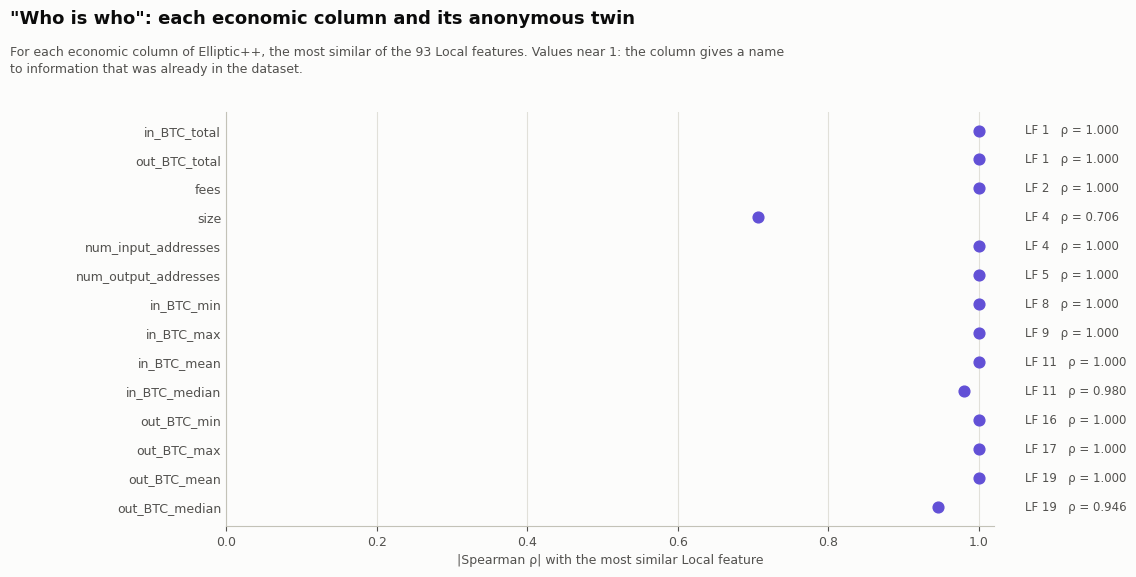

00_econ_vs_local.png written (73 KB).


In [20]:
closest = RHO.loc[ECON, LF].abs().idxmax(axis=1)
who = pd.DataFrame({'economic column': ECON, 'most similar Local feature': closest.to_numpy(),
                    'rho': [RHO.loc[c, closest[c]] for c in ECON]})
who['abs rho'] = who['rho'].abs()
save_table(who, 'econ_vs_local.csv')

fig, ax = plt.subplots(figsize=(12, 6))
fig.subplots_adjust(left=0.2, right=0.84, top=0.8, bottom=0.11)
ys = np.arange(len(who))
ax.scatter(who['abs rho'], ys, s=60, color=FAMILY_COLOR['D'], zorder=3)
ax.set_yticks(ys, who['economic column'])
ax.invert_yaxis()
ax.set_xlim(0, 1.02)
ax.set_xlabel('|Spearman ρ| with the most similar Local feature')
ax.grid(axis='x', color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis='y', length=0)
for y_, (_, r) in zip(ys, who.iterrows()):
    ax.text(1.04, y_, f"{r['most similar Local feature'].replace('Local_feature_', 'LF ')}   ρ = {r['rho']:.3f}",
            transform=ax.get_yaxis_transform(), va='center', fontsize=8.5, color=INK_2)
titles(fig, '"Who is who": each economic column and its anonymous twin',
       'For each economic column of Elliptic++, the most similar of the 93 Local features. '
       'Values near 1: the column gives a name\nto information that was already in the dataset.')
save_png(fig, '00_econ_vs_local.png')

## 11. A piece of the transaction graph

The 2-step neighbourhood of one illicit transaction: the transactions that pay it, those that pay them, those it pays and those they pay, with every edge among them. The transaction is chosen at random (with a fixed seed) among the illicit ones whose neighbourhood is readable in one picture: between 15 and 40 nodes, at least one transaction on each side, at least 4 layers and at most 12 nodes in a layer. The drawing is in layers (section 0): every arrow points to the right, in the direction of the money. It shows that the graph is directed and acyclic, how many unknown transactions surround an illicit one, and shapes such as chains (one input, one output) and fan-outs (one transaction paying many).

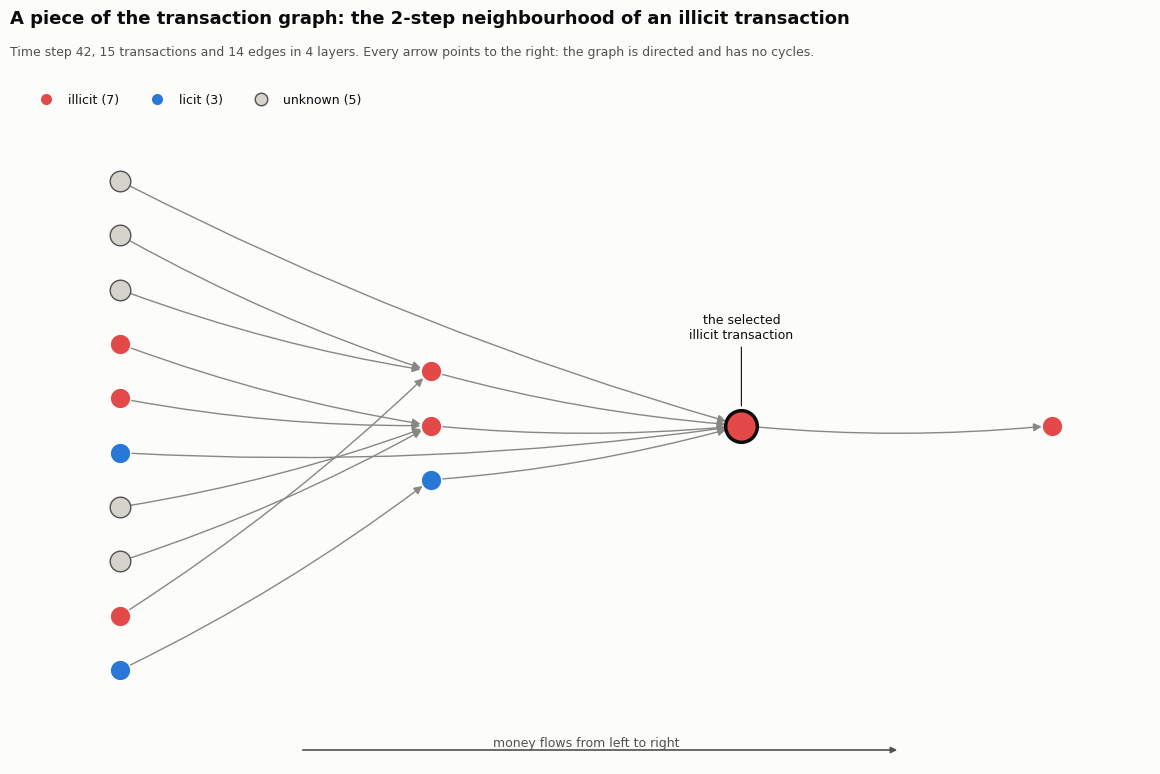

00_dag_example.png written (87 KB).
Selected transaction: txId 73042467 (time step 42).


In [21]:
def two_step(graph, v):
    """v, the nodes that pay v or pay those, and the nodes v pays or those pay (directed 2-step neighbourhood)."""
    before = set(graph.predecessors(v))
    after = set(graph.successors(v))
    nodes = {v} | before | after
    for u in before:
        nodes |= set(graph.predecessors(u))
    for u in after:
        nodes |= set(graph.successors(u))
    return nodes, before, after


def readable(graph, nodes):
    """Layers of the piece, if it fits one picture: 15-40 nodes, at least 4 layers, at most 12 nodes per layer."""
    if not 15 <= len(nodes) <= 40:
        return None
    layers = list(nx.topological_generations(graph.subgraph(nodes)))
    return layers if len(layers) >= 4 and max(len(layer) for layer in layers) <= 12 else None


rng = np.random.default_rng(DAG_SEED)
for v in rng.permutation(np.flatnonzero(CLS == 'illicit')):
    nodes, before, after = two_step(graph, int(v))
    if before and after and readable(graph, nodes):
        break
else:
    raise RuntimeError('no illicit transaction with a readable 2-step neighbourhood')
center = int(v)
piece = graph.subgraph(nodes)
assert nx.is_directed_acyclic_graph(piece)
pos = layered_layout(piece)
n_layers = 1 + max(x for x, _ in pos.values())
sizes = {u: 520 if u == center else 220 for u in piece.nodes}
classes_here = pd.Series(CLS[list(piece.nodes)]).value_counts().reindex(CLASSES, fill_value=0)

fig, ax = plt.subplots(figsize=(12, 8))
fig.subplots_adjust(left=0.03, right=0.97, top=0.82, bottom=0.08)
nx.draw_networkx_edges(piece, pos, ax=ax, edge_color=MUTED, width=1, arrows=True, arrowstyle='-|>', arrowsize=12,
                       nodelist=list(piece.nodes), node_size=[sizes[u] for u in piece.nodes],
                       connectionstyle='arc3,rad=0.05')
for c in CLASSES:
    members = [u for u in piece.nodes if CLS[u] == c]
    nx.draw_networkx_nodes(piece, pos, nodelist=members, ax=ax, node_color=CLASS_COLOR[c], node_size=220,
                           edgecolors=INK_2 if c == 'unknown' else SURFACE, linewidths=1)
nx.draw_networkx_nodes(piece, pos, nodelist=[center], ax=ax, node_color=CLASS_COLOR['illicit'], node_size=520,
                       edgecolors=INK, linewidths=2.5)
ax.annotate('the selected\nillicit transaction', xy=pos[center], xytext=(pos[center][0], pos[center][1] + 1.6),
            ha='center', fontsize=9, color=INK, arrowprops=dict(arrowstyle='-', color=INK, linewidth=0.8, shrinkB=14))
ax.axis('off')
ax.annotate('', xy=(0.75, 0.03), xytext=(0.25, 0.03), xycoords='figure fraction',
            arrowprops=dict(arrowstyle='-|>', color=INK_2, linewidth=1.2))
fig.text(0.5, 0.045, 'money flows from left to right', ha='center', va='bottom', fontsize=9, color=INK_2)
ax.legend(handles=[Line2D([], [], marker='o', linestyle='', markersize=9, markerfacecolor=CLASS_COLOR[c],
                          markeredgecolor=INK_2 if c == 'unknown' else SURFACE, label=f'{c} ({classes_here[c]})')
                   for c in CLASSES], loc='upper left', bbox_to_anchor=(0, 1.08), ncol=3, frameon=False)
titles(fig, 'A piece of the transaction graph: the 2-step neighbourhood of an illicit transaction',
       f'Time step {STEP[center]}, {piece.number_of_nodes()} transactions and {piece.number_of_edges()} edges '
       f'in {n_layers} layers. Every arrow points to the right: the graph is directed and has no cycles.')
save_png(fig, '00_dag_example.png')
print(f'Selected transaction: txId {TXID[center]} (time step {STEP[center]}).')

## 12. Final check and Drive sync

Every plot and table of this notebook must be on Drive, within the size limits.

In [22]:
PLOTS = ['00_class_share.png', '00_classes_per_timestep.png', '00_split_prevalence.png', '00_graph_size_per_timestep.png',
         '00_neighbor_classes.png', '00_without_unknown.png', '00_econ_by_class.png', '00_corr_all.png',
         '00_corr_econ.png', '00_econ_vs_local.png', '00_dag_example.png']
TABLES = ['dataset_card.csv', 'class_counts.csv', 'per_timestep.csv', 'split_composition.csv', 'graph_checks.csv',
          'neighbor_classes.csv', 'without_unknown.csv', 'econ_copies.csv', 'missing_econ.csv', 'econ_vs_local.csv']
for name in PLOTS:
    path = PLOT_DIR / name
    assert path.exists(), f'{name} is missing'
    with Image.open(path) as image:
        assert image.size[0] <= MAX_PIXELS[0] and image.size[1] <= MAX_PIXELS[1], name
    assert path.stat().st_size <= MAX_KB * 1000, name
for name in TABLES:
    assert (OUT_DIR / name).exists(), f'{name} is missing'
print(f'{len(PLOTS)} plots and {len(TABLES)} tables are complete.')

11 plots and 10 tables are complete.


In [23]:
drive.flush_and_unmount()
print('Every file is on Drive in', OUT_DIR, 'and', PLOT_DIR)

Every file is on Drive in /content/drive/MyDrive/UNIVERSITA/block-crypto/data/00-data-exploration and /content/drive/MyDrive/UNIVERSITA/block-crypto/data/plots
